### **Bagian 1: Ekstraksi Dataset**

Pada bagian ini, kita melakukan ekstraksi file zip dataset FER (Facial Expression Recognition) ke direktori lokal di Colab (`/content/dataset`) agar proses pembacaan data gambar selama training berlangsung dengan jauh lebih cepat.

Karena project ini bersifat **shared (bersama)**, terdapat **dua metode** yang bisa digunakan untuk mengakses dataset:

1. **Metode Google Drive (Rekomendasi)**:
   * Pastikan Anda sudah mount Drive.
   * Jika file zip berada di folder *"Shared with me"*, klik kanan file/folder tersebut di Google Drive -> **Organize** -> **Add shortcut** -> Pilih **My Drive** agar path `/content/drive/MyDrive/ML DL/DL/archive.zip` dapat terbaca.

2. **Metode Download Langsung (gdown)**:
   * Jika Anda tidak ingin melakukan mounting Drive, Anda cukup memasukkan **File ID** dari link shared file zip tersebut untuk langsung mengunduhnya secara otomatis.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
import os
import gdown
import re

# =========================================================================
# KONFIGURASI PATH & LINK / FILE ID
# =========================================================================
# Metode 1: Path jika menggunakan Google Drive (Shortcut harus sudah dibuat)
zip_path_drive = '/content/drive/MyDrive/ML DL/DL/archive.zip'

# Metode 2: Masukkan Link Google Drive atau File ID saja di sini
shared_link_or_id = 'https://drive.google.com/file/d/1r5IwzD4g07gEl1SCFQDjc9PUCD1_d3Lb/view?usp=sharing'
# =========================================================================

extract_path = '/content/dataset'
output_zip_local = '/content/archive.zip'

# Fungsi penolong untuk mengekstrak ID dari link Google Drive
def get_gdrive_id(link_or_id):
    if 'drive.google.com' in link_or_id:
        # Regex untuk mengambil ID di antara d/ dan /view atau sejenisnya
        match = re.search(r'/d/([^/]+)', link_or_id)
        if match:
            return match.group(1)
    return link_or_id

file_id_shared = get_gdrive_id(shared_link_or_id)

if not os.path.exists(extract_path):
    # Coba gunakan Metode 1 (Google Drive) terlebih dahulu
    if os.path.exists(zip_path_drive):
        print("Menggunakan dataset dari Google Drive...")
        with zipfile.ZipFile(zip_path_drive, 'r') as zip_ref:
            zip_ref.extractall(extract_path)
        print("Ekstraksi selesai dari Google Drive!")

    # Jika tidak ada di Drive, coba Metode 2 (Download langsung via gdown)
    elif file_id_shared and file_id_shared != 'MASUKKAN_FILE_ID_DISINI':
        print(f"Mengekstrak ID file: {file_id_shared}")
        print("Dataset di Google Drive lokal tidak ditemukan. Mencoba download langsung via gdown...")
        url = f'https://drive.google.com/uc?id={file_id_shared}'
        gdown.download(url, output_zip_local, quiet=False)

        if os.path.exists(output_zip_local):
            with zipfile.ZipFile(output_zip_local, 'r') as zip_ref:
                zip_ref.extractall(extract_path)
            print("Ekstraksi selesai dari file download!")
            try:
                os.remove(output_zip_local) # Bersihkan zip lokal setelah ekstrak
            except:
                pass
    else:
        raise FileNotFoundError("Dataset tidak ditemukan! Harap buat shortcut di Google Drive Anda atau masukkan File ID pada variabel 'shared_link_or_id'.")
else:
    print("Dataset sudah diekstrak sebelumnya.")

if os.path.exists(extract_path):
    print("Isi folder dataset:", os.listdir(extract_path))

Mengekstrak ID file: 1r5IwzD4g07gEl1SCFQDjc9PUCD1_d3Lb
Dataset di Google Drive lokal tidak ditemukan. Mencoba download langsung via gdown...


Downloading...
From (original): https://drive.google.com/uc?id=1r5IwzD4g07gEl1SCFQDjc9PUCD1_d3Lb
From (redirected): https://drive.google.com/uc?id=1r5IwzD4g07gEl1SCFQDjc9PUCD1_d3Lb&confirm=t&uuid=f9354ce9-3f20-497c-977a-543affe95d36
To: /content/archive.zip
100%|██████████| 63.3M/63.3M [00:00<00:00, 66.4MB/s]


Ekstraksi selesai dari file download!
Isi folder dataset: ['train', 'test']


### **Bagian 2: Preproses & Loading Data**

Di sini kita menggunakan `ImageDataGenerator` untuk melakukan normalisasi piksel (rescale ke `0-1`) serta augmentasi gambar pada data training (seperti rotasi, zoom, dan flip horizontal). Hal ini bertujuan agar model tidak mudah *overfitting* dan lebih tangguh ketika mendeteksi wajah secara real-time dari kamera dengan berbagai sudut.

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Tentukan path train dan test (sesuaikan jika folder di dalam zip memiliki nama berbeda)
# Umumnya dataset FER memiliki struktur: train/ dan test/ atau validation/
base_dir = extract_path
# Mari kita cari tahu struktur foldernya terlebih dahulu dengan mendaftar isinya
for root, dirs, files in os.walk(base_dir):
    level = root.replace(base_dir, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}{os.path.basename(root)}/")

dataset/
    train/
        fear/
        disgust/
        surprise/
        sad/
        angry/
        neutral/
        happy/
    test/
        fear/
        disgust/
        surprise/
        sad/
        angry/
        neutral/
        happy/


In [4]:
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_HEIGHT = 48
IMG_WIDTH = 48
BATCH_SIZE = 64

base_dir = extract_path
subdirs = os.listdir(base_dir)
train_dir = os.path.join(base_dir, 'train') if 'train' in subdirs else base_dir
test_dir = os.path.join(base_dir, 'test') if 'test' in subdirs else (os.path.join(base_dir, 'validation') if 'validation' in subdirs else base_dir)

# 1. Data Generator Grayscale (untuk Vanilla Custom Residual Model 48x48)
train_datagen_gray = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True
)
val_datagen_gray = ImageDataGenerator(rescale=1./255)

train_gen_gray = train_datagen_gray.flow_from_directory(
    train_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    class_mode='categorical'
)

val_gen_gray = val_datagen_gray.flow_from_directory(
    test_dir,
    target_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    color_mode='grayscale',
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_gen_gray.class_indices)
class_labels = list(train_gen_gray.class_indices.keys())
print(f"Jumlah Kelas: {num_classes} -> {class_labels}")

Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.
Jumlah Kelas: 7 -> ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


### **Bagian 2b: EDA dan Pemeriksaan Kualitas Data**

Bagian ini **tidak mengubah dataset dan tidak melatih model**:
1. Menghitung jumlah citra per kelas dan membuat grafik distribusi kelas.
2. Menampilkan 8 contoh citra acak untuk setiap kelas.
3. Memeriksa kualitas data: file rusak, ukuran tidak seragam, citra polos (kemungkinan bukan wajah), duplikat di dalam folder train, dan citra test yang juga ada di folder train.

,Train,Test,% Train,% Test
angry,3995,958,13.9,13.3
disgust,436,111,1.5,1.5
fear,4097,1024,14.3,14.3
happy,7215,1774,25.1,24.7
neutral,4965,1233,17.3,17.2
sad,4830,1247,16.8,17.4
surprise,3171,831,11.0,11.6


Total train: 28709 | Total test: 7178


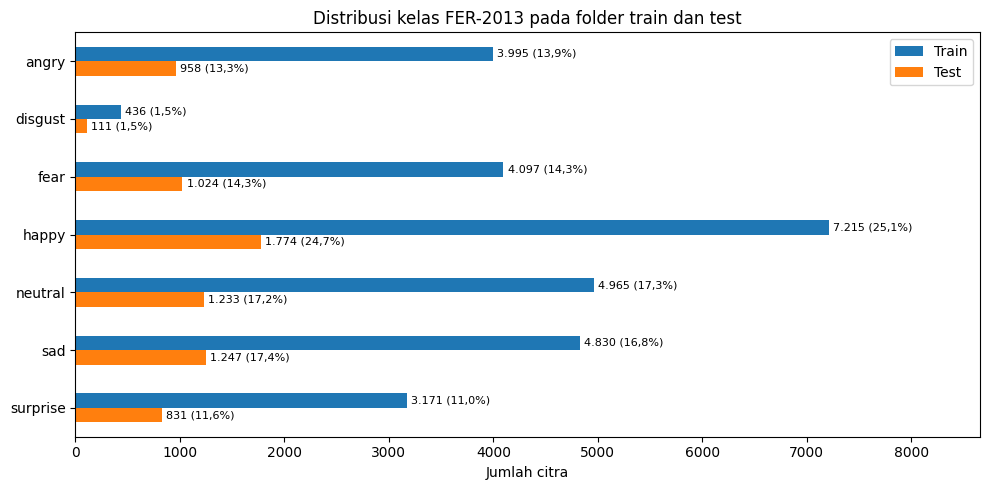

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Hitung jumlah citra per kelas pada folder train dan test
jumlah = {}
for kelas in class_labels:
    jumlah[kelas] = {
        'Train': len(os.listdir(os.path.join(train_dir, kelas))),
        'Test': len(os.listdir(os.path.join(test_dir, kelas))),
    }
tabel_kelas = pd.DataFrame(jumlah).T
tabel_kelas['% Train'] = (tabel_kelas['Train'] / tabel_kelas['Train'].sum() * 100).round(1)
tabel_kelas['% Test'] = (tabel_kelas['Test'] / tabel_kelas['Test'].sum() * 100).round(1)
display(tabel_kelas)
print('Total train:', tabel_kelas['Train'].sum(), '| Total test:', tabel_kelas['Test'].sum())

# Grafik distribusi kelas dengan angka di samping bar
ax = tabel_kelas[['Train', 'Test']].plot(kind='barh', figsize=(10, 5), color=['tab:blue', 'tab:orange'])
for bar_grup, kolom in zip(ax.containers, ['Train', 'Test']):
    label = []
    for jumlah_citra, persen in zip(tabel_kelas[kolom], tabel_kelas['% ' + kolom]):
        label.append(f"{jumlah_citra:,}".replace(',', '.') + f" ({str(persen).replace('.', ',')}%)")
    ax.bar_label(bar_grup, labels=label, padding=3, fontsize=8)

ax.set_title('Distribusi kelas FER-2013 pada folder train dan test')
ax.set_xlabel('Jumlah citra')
ax.set_xlim(0, tabel_kelas['Train'].max() * 1.2)   # ruang kosong untuk angka
ax.invert_yaxis()
plt.tight_layout()
plt.show()

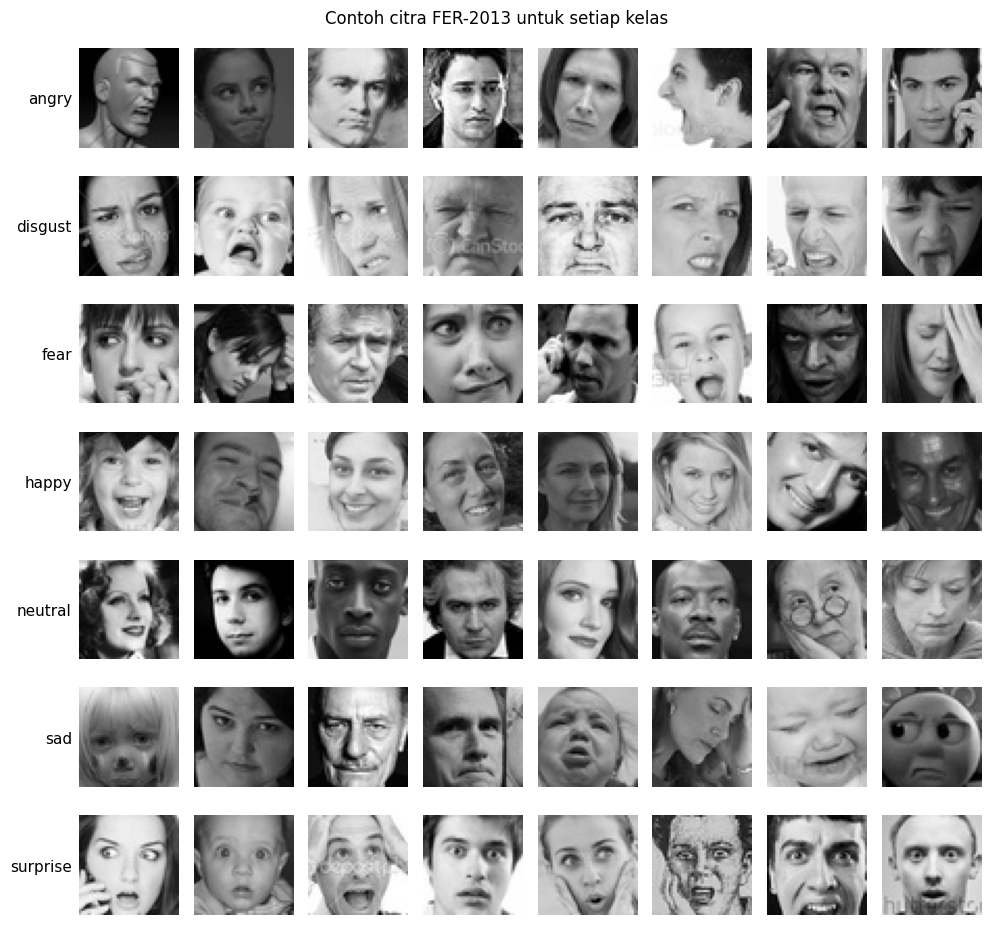

In [6]:
import random
from PIL import Image

# Contoh 8 citra acak untuk setiap kelas
random.seed(42)
fig, axes = plt.subplots(len(class_labels), 8, figsize=(10, 9.5))
for i, kelas in enumerate(class_labels):
    folder = os.path.join(train_dir, kelas)
    contoh = random.sample(sorted(os.listdir(folder)), 8)
    for j, nama_file in enumerate(contoh):
        axes[i, j].imshow(Image.open(os.path.join(folder, nama_file)), cmap='gray', vmin=0, vmax=255)
        axes[i, j].axis('off')
    axes[i, 0].text(-4, 24, kelas, ha='right', va='center', fontsize=11)
plt.suptitle('Contoh citra FER-2013 untuk setiap kelas')
plt.tight_layout()
plt.show()

In [7]:
import hashlib
import numpy as np

# Pemeriksaan kualitas data (tidak ada file yang dihapus, hanya dihitung)
rusak, ukuran_beda, polos = [], [], []
hash_train, hash_test = {}, {}

for folder_utama, kamus_hash in [(train_dir, hash_train), (test_dir, hash_test)]:
    for kelas in class_labels:
        folder = os.path.join(folder_utama, kelas)
        for nama_file in os.listdir(folder):
            path = os.path.join(folder, nama_file)
            try:
                img = Image.open(path)
                img.load()
            except Exception:
                rusak.append(path)
                continue
            if img.size != (48, 48) or img.mode != 'L':
                ukuran_beda.append(path)
            piksel = np.array(img)
            if piksel.std() < 5:      # citra polos (hampir satu warna), kemungkinan bukan wajah
                polos.append(path)
            kode = hashlib.md5(piksel.tobytes()).hexdigest()   # "sidik jari" isi citra
            kamus_hash.setdefault(kode, []).append(kelas)

duplikat_train = sum(len(v) - 1 for v in hash_train.values() if len(v) > 1)
duplikat_beda_label = sum(1 for v in hash_train.values() if len(set(v)) > 1)
test_ada_di_train = sum(len(v) for k, v in hash_test.items() if k in hash_train)

print('File rusak / tidak bisa dibuka           :', len(rusak))
print('Ukuran bukan 48x48 grayscale             :', len(ukuran_beda))
print('Citra polos (std piksel < 5)             :', len(polos))
print('Duplikat di dalam folder train           :', duplikat_train)
print('  - kelompok duplikat dengan label beda  :', duplikat_beda_label)
print('Citra test yang juga ada di folder train :', test_ada_di_train)

File rusak / tidak bisa dibuka           : 0
Ukuran bukan 48x48 grayscale             : 0
Citra polos (std piksel < 5)             : 14
Duplikat di dalam folder train           : 1236
  - kelompok duplikat dengan label beda  : 39
Citra test yang juga ada di folder train : 568


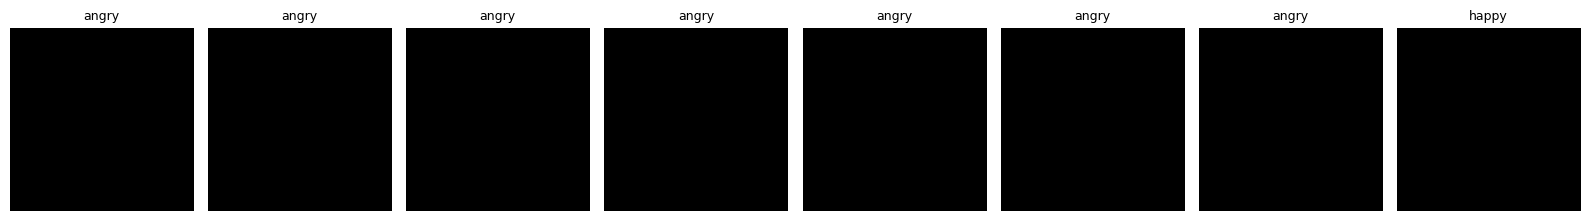

In [8]:
# Tampilkan beberapa citra polos yang ditemukan
if polos:
    n = min(8, len(polos))
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.4))
    axes = np.atleast_1d(axes)
    for ax, path in zip(axes, polos[:n]):
        ax.imshow(Image.open(path), cmap='gray', vmin=0, vmax=255)
        ax.set_title(path.split(os.sep)[-2], fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Tidak ada citra polos.')

### **Bagian 3: Arsitektur Model Custom Residual CNN**

Kita menyusun model **Custom Residual CNN** yang terdiri atas 1 konvolusi awal dan 3 *residual block* (64, 128, dan 256 filter), diikuti `MaxPooling2D`, `Dropout`, dan kepala klasifikasi `Dense`. *Skip connection* pada residual block membantu aliran gradien, sedangkan ukuran modelnya tetap kecil (±1,3 juta parameter) sehingga cocok untuk aplikasi real-time.

In [9]:
import tensorflow as tf
from tensorflow.keras import layers, Model

class ResidualBlock(layers.Layer):
    def __init__(self, filters, stride=1, **kwargs):
        super(ResidualBlock, self).__init__(**kwargs)
        self.filters = filters
        self.stride = stride

        # Main Branch
        self.conv1 = layers.Conv2D(filters, (3, 3), strides=stride, padding='same', use_bias=False)
        self.bn1 = layers.BatchNormalization()
        self.conv2 = layers.Conv2D(filters, (3, 3), strides=1, padding='same', use_bias=False)
        self.bn2 = layers.BatchNormalization()

        # Shortcut Branch
        if stride != 1:
            self.shortcut = tf.keras.Sequential([
                layers.Conv2D(filters, (1, 1), strides=stride, padding='same', use_bias=False),
                layers.BatchNormalization()
            ])
        else:
            self.shortcut = lambda x, training=False: x

    def call(self, inputs, training=False):
        shortcut = self.shortcut(inputs, training=training)

        x = self.conv1(inputs)
        x = self.bn1(x, training=training)
        x = tf.nn.relu(x)

        x = self.conv2(x)
        x = self.bn2(x, training=training)

        x = layers.add([x, shortcut])
        return tf.nn.relu(x)

    def get_config(self):
        config = super(ResidualBlock, self).get_config()
        config.update({
            "filters": self.filters,
            "stride": self.stride
        })
        return config


class AdvancedResidualFERModel(Model):
    def __init__(self, num_classes, **kwargs):
        super(AdvancedResidualFERModel, self).__init__(**kwargs)
        self.init_conv = layers.Conv2D(64, (3, 3), padding='same', activation='relu')
        self.init_bn = layers.BatchNormalization()

        self.res_block1 = ResidualBlock(64, stride=1)
        self.pool1 = layers.MaxPooling2D(2, 2)
        self.drop1 = layers.Dropout(0.3)

        self.res_block2 = ResidualBlock(128, stride=2)
        self.pool2 = layers.MaxPooling2D(2, 2)
        self.drop2 = layers.Dropout(0.3)

        self.res_block3 = ResidualBlock(256, stride=2)
        self.gap = layers.GlobalAveragePooling2D()
        self.dense = layers.Dense(256, activation='relu')
        self.bn_dense = layers.BatchNormalization()
        self.drop_dense = layers.Dropout(0.5)
        self.out = layers.Dense(num_classes, activation='softmax')

    def call(self, inputs, training=False):
        x = self.init_conv(inputs)
        x = self.init_bn(x, training=training)

        x = self.res_block1(x, training=training)
        x = self.pool1(x)
        x = self.drop1(x, training=training)

        x = self.res_block2(x, training=training)
        x = self.pool2(x)
        x = self.drop2(x, training=training)

        x = self.res_block3(x, training=training)
        x = self.gap(x)

        x = self.dense(x)
        x = self.bn_dense(x, training=training)
        x = self.drop_dense(x, training=training)
        return self.out(x)

vanilla_model = AdvancedResidualFERModel(num_classes=num_classes)
dummy_input = tf.zeros((1, IMG_HEIGHT, IMG_WIDTH, 1))
_ = vanilla_model(dummy_input)

vanilla_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("--- Arsitektur Model Custom Residual CNN (Vanilla OOP) ---")
vanilla_model.summary()

--- Arsitektur Model Custom Residual CNN (Vanilla OOP) ---


Model: "advanced_residual_fer_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (1, 48, 48, 64)        │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (1, 48, 48, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_block (ResidualBlock)  │ ?                      │        74,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_block_1                │ ?                      │       230,912 │
│ (ResidualBlock)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ residual_block_2                │ ?                      │       920,576 │
│ (ResidualBlock)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 256)               │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (1, 256)               │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 7)                 │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,295,239 (4.94 MB)

 Trainable params: 1,292,039 (4.93 MB)

 Non-trainable params: 3,200 (12.50 KB)

### **Bagian 4: Training Model (Vanila)**

Untuk menghindari training yang terlalu lama, kita menambahkan callback `EarlyStopping` dengan parameter `patience=5` (berhenti jika `val_loss` tidak membaik dalam 5 epoch). Bobot dengan `val_accuracy` terbaik otomatis disimpan oleh `ModelCheckpoint` dalam format `.weights.h5` di Google Drive. File inilah yang nanti dipakai aplikasi.

In [10]:
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
import numpy as np
import os
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

drive_dest_folder = '/content/drive/MyDrive/ML DL/DL/UTS/Output'
os.makedirs(drive_dest_folder, exist_ok=True)

class_series = train_gen_gray.classes
class_labels_indices = np.unique(class_series)

computed_weights = compute_class_weight(
    class_weight='balanced',
    classes=class_labels_indices,
    y=class_series
)
class_weights_dict = dict(zip(class_labels_indices, computed_weights))
print("Bobot kelas:", {class_labels[i]: round(float(w), 4) for i, w in class_weights_dict.items()})

# Setup Callbacks
checkpoint_vanilla = ModelCheckpoint(
    filepath=os.path.join(drive_dest_folder, 'best_vanilla_modified_fer_model.weights.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,
    mode='max',
    verbose=1
)

early_stop_vanilla = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_vanilla = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

# Pelatihan Model dengan Class Weight
history_vanilla = vanilla_model.fit(
    train_gen_gray,
    epochs=20,
    validation_data=val_gen_gray,
    class_weight=class_weights_dict,  # class weight diterapkan di sini
    callbacks=[checkpoint_vanilla, early_stop_vanilla, reduce_lr_vanilla]
)

Bobot kelas: {'angry': 1.0266, 'disgust': 9.4066, 'fear': 1.001, 'happy': 0.5684, 'neutral': 0.826, 'sad': 0.8491, 'surprise': 1.2934}
Epoch 1/20
448/449 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.1586 - loss: 2.4055
Epoch 1: val_accuracy improved from None to 0.01867, saving model to /content/drive/MyDrive/ML DL/DL/UTS/Output/best_vanilla_modified_fer_model.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ML DL/DL/UTS/Output/best_vanilla_modified_fer_model.weights.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 60s 91ms/step - accuracy: 0.1605 - loss: 2.2406 - val_accuracy: 0.0187 - val_loss: 2.1384 - learning_rate: 0.0010
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.1679 - loss: 2.0364
Epoch 2: val_accuracy improved from 0.01867 to 0.19699, saving model to /content/drive/MyDrive/ML DL/DL/UTS/Output/best_vanilla_modified_fer_model.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/ML DL/DL/UTS/Output/best_vanilla_modified_fer_model.weig

### **Bagian 5: Pendekatan Transfer Learning (ResNet50)**

Di sini, kita membangun model alternatif berbasis **ResNet50** dengan teknik Transfer Learning untuk pemrosesan klasifikasi ekspresi wajah yang lebih kompleks. Model ini dikonfigurasi untuk melakukan penyesuaian (*fine-tuning*) pada beberapa layer teratasnya.

In [12]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, Model

NEW_IMG_SIZE = 96

class OOPResNet50FERModel(Model):
    def __init__(self, num_classes, **kwargs):
        super(OOPResNet50FERModel, self).__init__(**kwargs)

        self.base_model = ResNet50(
            input_shape=(NEW_IMG_SIZE, NEW_IMG_SIZE, 3),
            include_top=False,
            weights='imagenet'
        )

        # Fitur unik 2: hanya 30 layer teratas ResNet50 yang dilatih ulang
        self.base_model.trainable = True
        for layer in self.base_model.layers[:-30]:
            layer.trainable = False

        self.gap = layers.GlobalAveragePooling2D()
        self.dense = layers.Dense(256, activation='relu')
        self.bn = layers.BatchNormalization()
        self.dropout = layers.Dropout(0.5)
        self.out = layers.Dense(num_classes, activation='softmax')

    def call(self, inputs, training=False):
        x = tf.image.grayscale_to_rgb(inputs)
        x = tf.image.resize(x, (NEW_IMG_SIZE, NEW_IMG_SIZE))

        # Kembalikan skala piksel ke 0-255 karena preprocess_input ResNet50 membutuhkannya
        x = x * 255.0
        x = tf.keras.applications.resnet50.preprocess_input(x)

        x = self.base_model(x, training=training)
        x = self.gap(x)
        x = self.dense(x)
        x = self.bn(x, training=training)
        x = self.dropout(x, training=training)
        return self.out(x)

resnet_model = OOPResNet50FERModel(num_classes=num_classes)
dummy_input_gray = tf.zeros((1, IMG_HEIGHT, IMG_WIDTH, 1))
_ = resnet_model(dummy_input_gray)

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("--- Arsitektur Model ResNet50 Transfer Learning (OOP) ---")
resnet_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
--- Arsitektur Model ResNet50 Transfer Learning (OOP) ---


Model: "oop_res_net50fer_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (1, 256)               │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (1, 256)               │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (1, 7)                 │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,115,079 (91.99 MB)

 Trainable params: 14,977,031 (57.13 MB)

 Non-trainable params: 9,138,048 (34.86 MB)

### **Bagian 6: Pelatihan Model Pre-trained OOP (ResNet50)**

Sekarang kita lakukan proses training pada model berbasis ResNet50 OOP ini dengan menggunakan data generator yang dikonversi langsung secara internal di dalam model.

In [13]:
import numpy as np
import os
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

drive_dest_folder = '/content/drive/MyDrive/ML DL/DL/UTS/Output'
os.makedirs(drive_dest_folder, exist_ok=True)

# Menghitung bobot secara otomatis berdasarkan proporsi jumlah data tiap kelas
class_series = train_gen_gray.classes
class_labels_indices = np.unique(class_series)

computed_weights = compute_class_weight(
    class_weight='balanced',
    classes=class_labels_indices,
    y=class_series
)
class_weights_dict = dict(zip(class_labels_indices, computed_weights))

# Setup Callbacks untuk ResNet50
checkpoint_resnet = ModelCheckpoint(
    filepath=os.path.join(drive_dest_folder, 'best_resnet_modified_fer.weights.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,
    mode='max',
    verbose=1
)

early_stop_resnet = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr_resnet = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

print("=== MEMULAI PELATIHAN MODEL RESNET50 (TRANSFER LEARNING) ===")
# Menggunakan train_gen_gray & val_gen_gray langsung karena konversi RGB/Resize sudah ditangani di dalam layer call() model
history_resnet = resnet_model.fit(
    train_gen_gray,
    epochs=20,
    validation_data=val_gen_gray,
    class_weight=class_weights_dict,  # Menggunakan Class Weight Balancing
    callbacks=[checkpoint_resnet, early_stop_resnet, reduce_lr_resnet]
)

=== MEMULAI PELATIHAN MODEL RESNET50 (TRANSFER LEARNING) ===
Epoch 1/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.2328 - loss: 2.6174
Epoch 1: val_accuracy improved from None to 0.42797, saving model to /content/drive/MyDrive/ML DL/DL/UTS/Output/best_resnet_modified_fer.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ML DL/DL/UTS/Output/best_resnet_modified_fer.weights.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 92s 144ms/step - accuracy: 0.2817 - loss: 2.2546 - val_accuracy: 0.4280 - val_loss: 1.7539 - learning_rate: 1.0000e-04
Epoch 2/20
449/449 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.3767 - loss: 1.7453
Epoch 2: val_accuracy improved from 0.42797 to 0.49262, saving model to /content/drive/MyDrive/ML DL/DL/UTS/Output/best_resnet_modified_fer.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/ML DL/DL/UTS/Output/best_resnet_modified_fer.weights.h5
449/449 ━━━━━━━━━━━━━━━━━━━━ 30s 66ms/step - accuracy: 0.3899 - loss: 1.7027 - val_accurac

### **Bagian 7: Grafik Akurasi dan Loss**

Setelah training selesai, kita memvisualisasikan grafik akurasi dan loss data latih serta validasi untuk melihat apakah model mengalami *underfitting* atau *overfitting*.

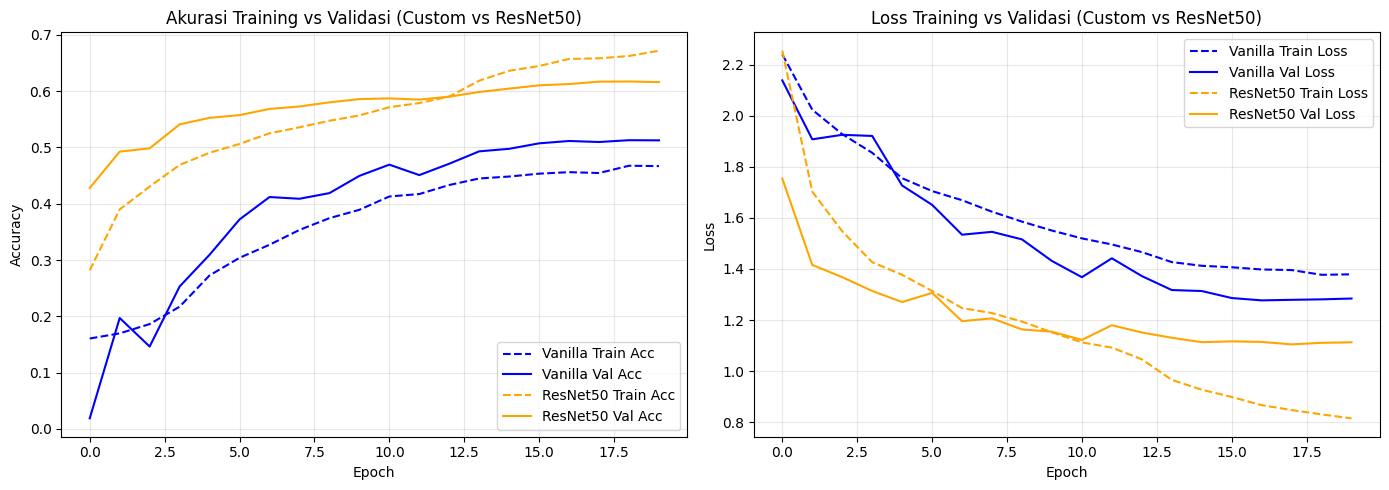

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Plot Akurasi Validasi
plt.subplot(1, 2, 1)
plt.plot(history_vanilla.history['accuracy'], label='Vanilla Train Acc', linestyle='--', color='blue')
plt.plot(history_vanilla.history['val_accuracy'], label='Vanilla Val Acc', color='blue')
plt.plot(history_resnet.history['accuracy'], label='ResNet50 Train Acc', linestyle='--', color='orange')
plt.plot(history_resnet.history['val_accuracy'], label='ResNet50 Val Acc', color='orange')
plt.title('Akurasi Training vs Validasi (Custom vs ResNet50)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot Loss Validasi
plt.subplot(1, 2, 2)
plt.plot(history_vanilla.history['loss'], label='Vanilla Train Loss', linestyle='--', color='blue')
plt.plot(history_vanilla.history['val_loss'], label='Vanilla Val Loss', color='blue')
plt.plot(history_resnet.history['loss'], label='ResNet50 Train Loss', linestyle='--', color='orange')
plt.plot(history_resnet.history['val_loss'], label='ResNet50 Val Loss', color='orange')
plt.title('Loss Training vs Validasi (Custom vs ResNet50)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### **Bagian 8: Evaluasi Detail dengan Confusion Matrix**

Pada bagian ini, kita memuat **bobot terbaik yang tersimpan di Google Drive** (file yang sama dengan yang dipakai aplikasi), lalu melakukan prediksi pada seluruh data test untuk menghasilkan **Confusion Matrix** dan **Classification Report**.

Bobot terbaik berhasil dimuat dari Google Drive.

   MEMPROSES EVALUASI MODEL: CUSTOM RESIDUAL CNN (VANILLA)
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step


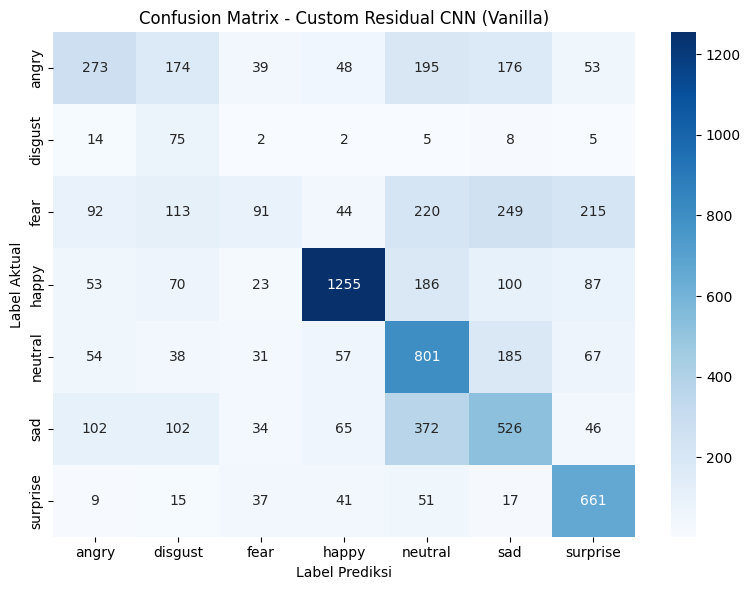


Laporan Klasifikasi (Custom Residual CNN (Vanilla)):
              precision    recall  f1-score   support

       angry       0.46      0.28      0.35       958
     disgust       0.13      0.68      0.21       111
        fear       0.35      0.09      0.14      1024
       happy       0.83      0.71      0.76      1774
     neutral       0.44      0.65      0.52      1233
         sad       0.42      0.42      0.42      1247
    surprise       0.58      0.80      0.67       831

    accuracy                           0.51      7178
   macro avg       0.46      0.52      0.44      7178
weighted avg       0.53      0.51      0.50      7178


   MEMPROSES EVALUASI MODEL: PRE-TRAINED RESNET50 (TRANSFER LEARNING)
113/113 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step


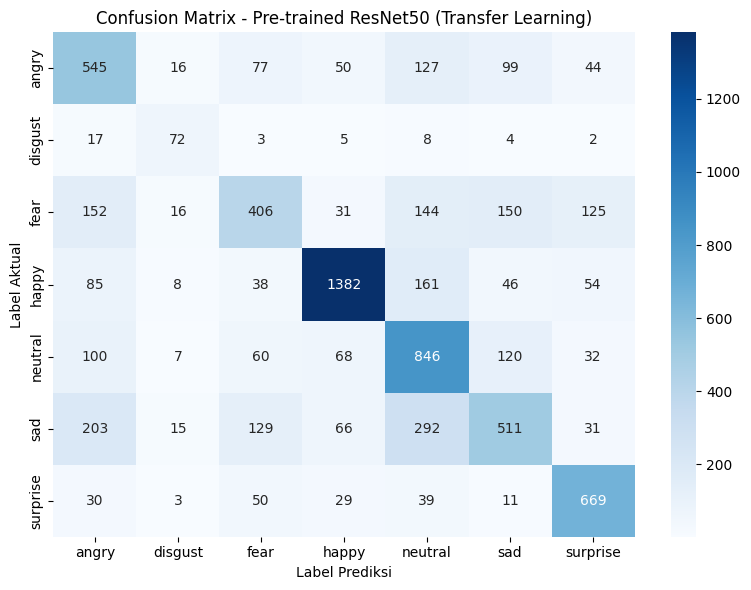


Laporan Klasifikasi (Pre-trained ResNet50 (Transfer Learning)):
              precision    recall  f1-score   support

       angry       0.48      0.57      0.52       958
     disgust       0.53      0.65      0.58       111
        fear       0.53      0.40      0.45      1024
       happy       0.85      0.78      0.81      1774
     neutral       0.52      0.69      0.59      1233
         sad       0.54      0.41      0.47      1247
    surprise       0.70      0.81      0.75       831

    accuracy                           0.62      7178
   macro avg       0.59      0.61      0.60      7178
weighted avg       0.62      0.62      0.61      7178



In [15]:
import os
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

def evaluasi_model_lengkap(model_obj, val_gen, nama_model, class_names):
    print("\n" + "="*60)
    print(f"   MEMPROSES EVALUASI MODEL: {nama_model.upper()}")
    print("="*60)

    val_gen.shuffle = False
    val_gen.reset()

    y_pred_probs = model_obj.predict(val_gen, verbose=1)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes

    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f'Confusion Matrix - {nama_model}')
    plt.ylabel('Label Aktual')
    plt.xlabel('Label Prediksi')
    plt.tight_layout()
    plt.show()

    print(f"\nLaporan Klasifikasi ({nama_model}):")
    print(classification_report(y_true, y_pred, target_names=class_names))

# Muat bobot terbaik dari Google Drive (file yang sama dengan yang dipakai aplikasi)
drive_dest_folder = '/content/drive/MyDrive/ML DL/DL/UTS/Output'
vanilla_model.load_weights(os.path.join(drive_dest_folder, 'best_vanilla_modified_fer_model.weights.h5'))
resnet_model.load_weights(os.path.join(drive_dest_folder, 'best_resnet_modified_fer.weights.h5'))
print("Bobot terbaik berhasil dimuat dari Google Drive.")

# 1. Evaluasi Model Custom Vanilla
evaluasi_model_lengkap(
    model_obj=vanilla_model,
    val_gen=val_gen_gray,
    nama_model="Custom Residual CNN (Vanilla)",
    class_names=class_labels
)

# 2. Evaluasi Model Pre-trained ResNet50
evaluasi_model_lengkap(
    model_obj=resnet_model,
    val_gen=val_gen_gray,
    nama_model="Pre-trained ResNet50 (Transfer Learning)",
    class_names=class_labels
)